# Seed stability, sortability and assumptions


Separates variability over dataset seeds from variability over model seeds. Sortability and R²-SortnRegress are recalculated on the same 2000-observation benchmark instances as the other models.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
sources = th.load_aligned_sources()
benchmark_data = sources["benchmark_data"]
benchmark_data = sources["benchmark_data"]


## Stability and assumption effects


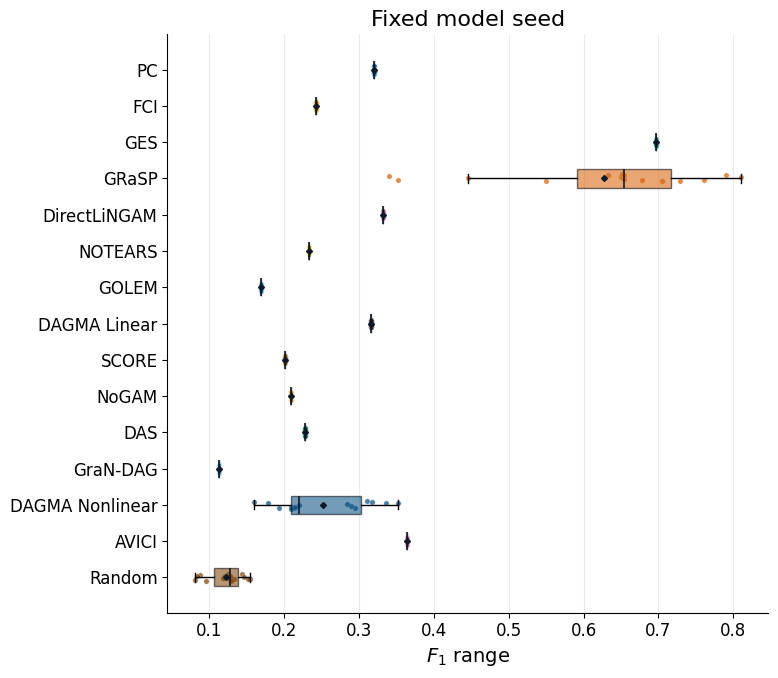

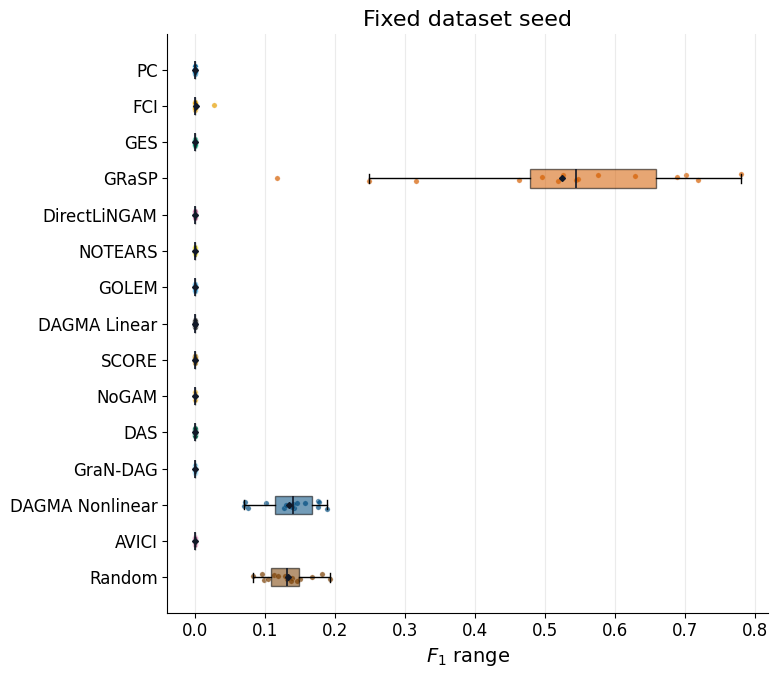

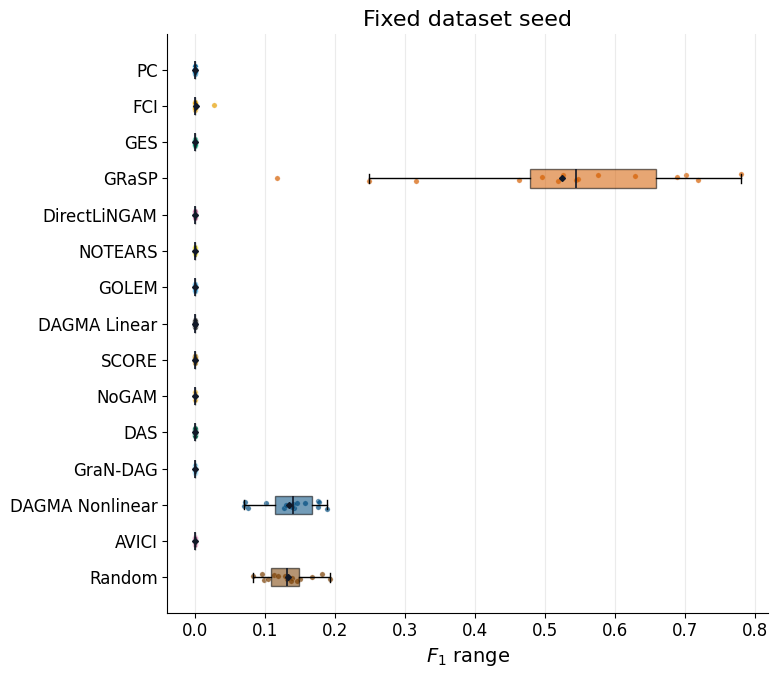

In [2]:
fig_dataset, _, dataset_stability = fv.plot_dataset_seed_stability(
    benchmark_data,
    metric="f1",
    variability="range",
    n_nodes=20,
    graph_type="EB",
    noise="Gaussian",
    mechanism="Linear",
    obs_conf=0,
    lat_conf=0,
    min_coverage_fraction=0.8,
    title="Fixed model seed",
    ylabel="$F_1$ range",
    figsize=(8, 7),
    font_size=14,
    title_size=16,
    plot_kind="box",
    model_axis="y",
)
fixed_model_pdf = th.save_pdf(fig_dataset, "Fixed_Model_Seed_F1.pdf")
display(fig_dataset)
plt.close(fig_dataset)
fig_model, _, model_stability = fv.plot_model_seed_stability(
    benchmark_data,
    metric="f1",
    variability="range",
    n_nodes=20,
    graph_type="EB",
    noise="Gaussian",
    mechanism="Linear",
    obs_conf=0,
    lat_conf=0,
    min_coverage_fraction=0.8,
    title="Fixed dataset seed",
    ylabel="$F_1$ range",
    figsize=(8, 7),
    font_size=14,
    title_size=16,
    plot_kind="box",
    model_axis="y",
)
fixed_dataset_pdf = th.save_pdf(fig_model, "Fixed_Dataset_Seed_F1.pdf")
display(fig_model)


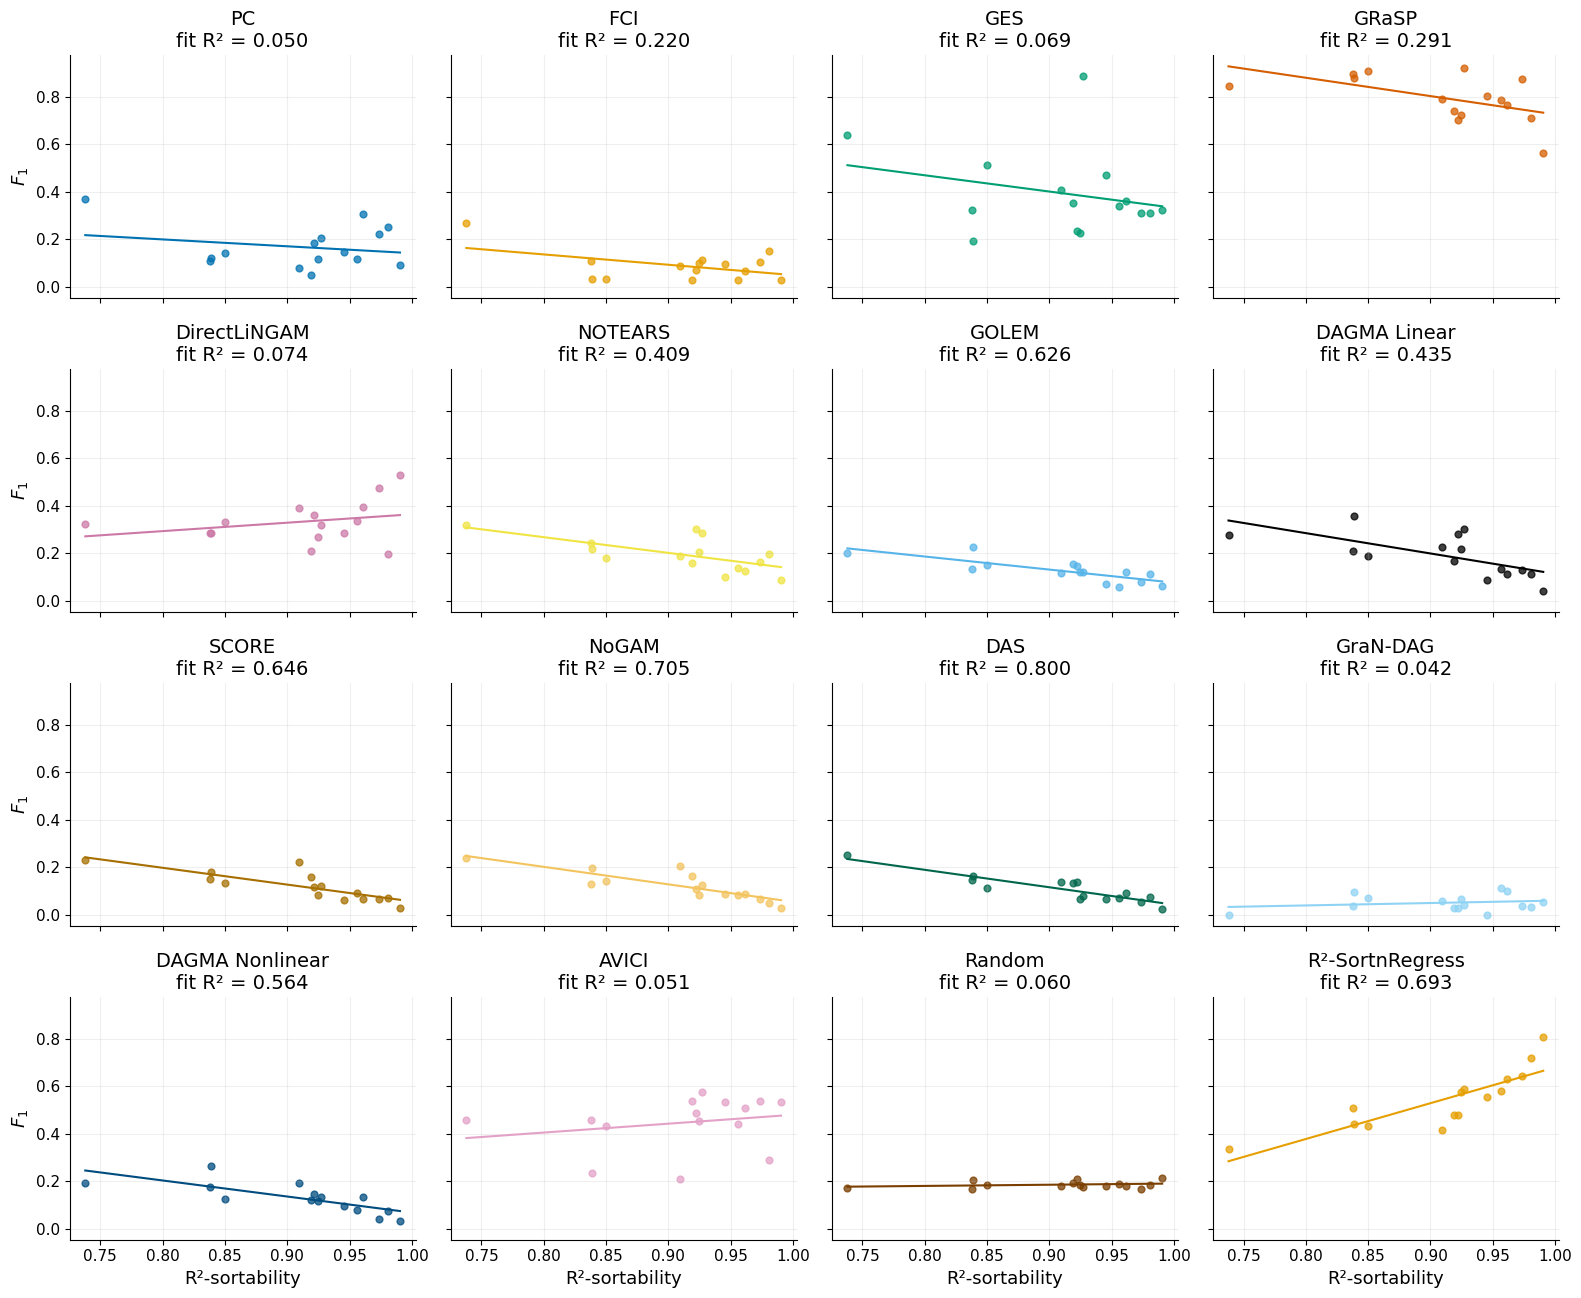

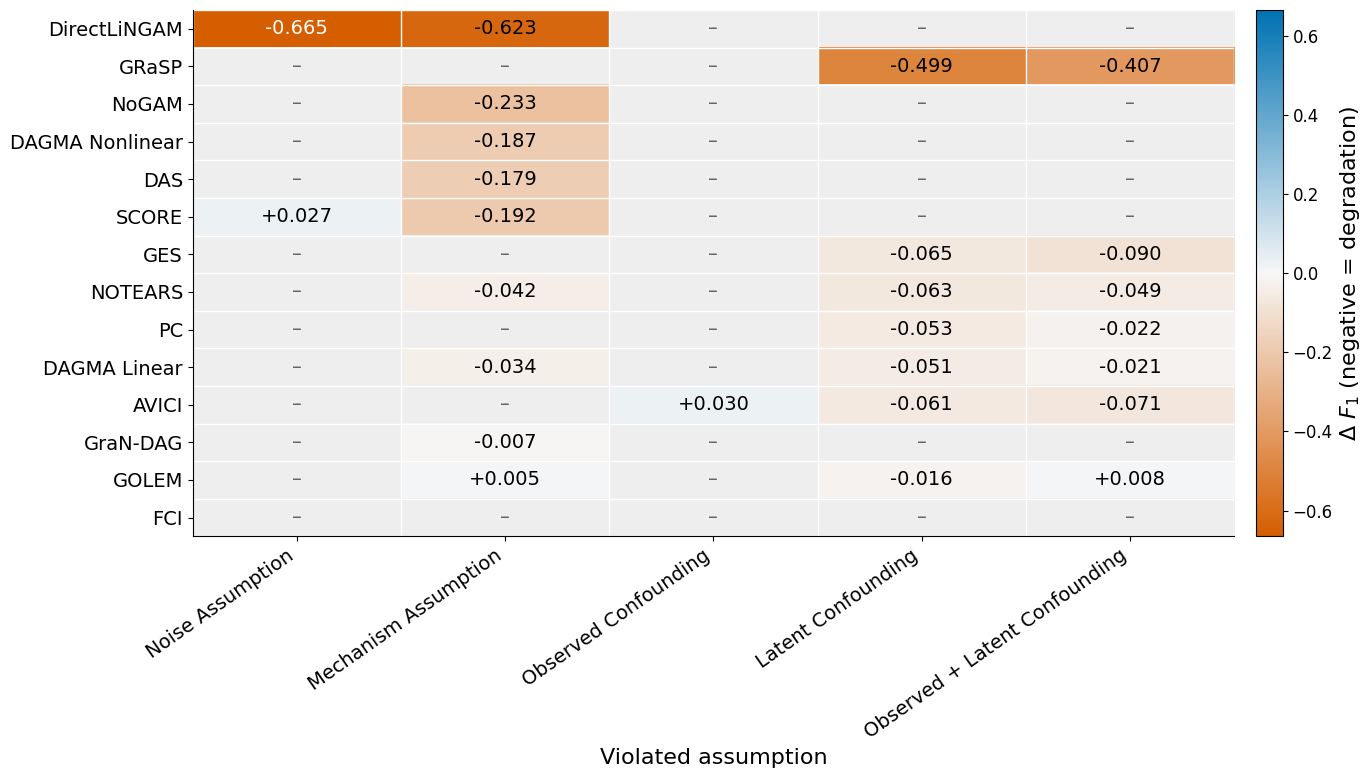

In [3]:
plt.close(fig_model)
fig_var, _, varsortability_output = fv.plot_varsortability_vs_f1(
    benchmark_data,
    metric="f1",
    sortability="r2_sortability",
    include_r2_sort_regress=True,
    varsortability_values=th.raw_sortability(),
    r2_sort_regress_values=th.r2_sort_regress(),
    datasets=th.OOD_FAMILIES[0],
    coverage_policy="complete",
    columns=4,
    font_size=13,
    title_size=14,
    show_metric_title=False,
    show_model_titles=True,
    project_root=ROOT,
)
varsort_pdf = th.save_pdf(fig_var, "R2_Sortability_vs_F1.pdf")
display(fig_var)
plt.close(fig_var)
fig_assumption, _, assumption_output = fv.plot_assumption_degradation_heatmap(
    benchmark_data,
    metric="f1",
    assumptions=fv.DEFAULT_ASSUMPTIONS,
    uncertainty="sd",
    show_metric_title=False,
    show_comparisons=False,
    figsize=(14, 8),
    font_size=16,
)
assumption_pdf = th.save_pdf(fig_assumption, "model_assumption_degradation_F1.pdf")
display(fig_assumption)
plt.close(fig_assumption)


## Stability under non-Gaussian mixed mechanisms


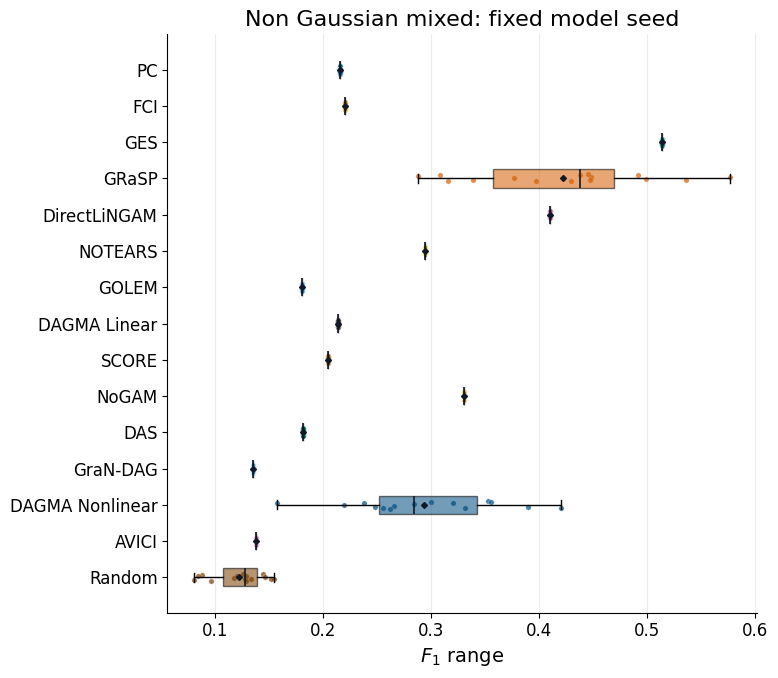

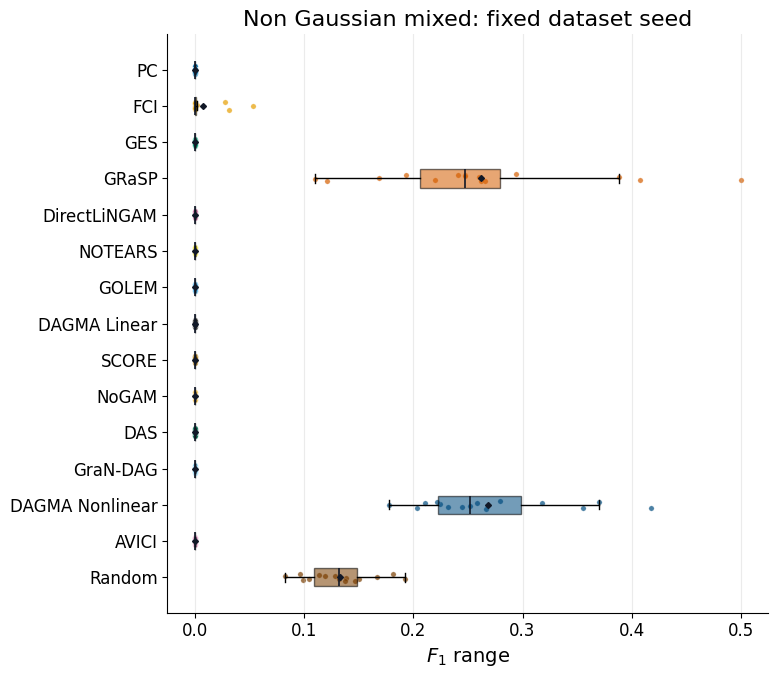

In [4]:
fig_dataset, _, dataset_stability = fv.plot_dataset_seed_stability(
    benchmark_data,
    metric="f1",
    variability="range",
    n_nodes=20,
    graph_type="EB",
    noise="Non_Gaussian",
    mechanism="Mixed",
    obs_conf=0,
    lat_conf=0,
    min_coverage_fraction=0.8,
    title="Non Gaussian mixed: fixed model seed",
    ylabel="$F_1$ range",
    figsize=(8, 7),
    font_size=14,
    title_size=16,
    plot_kind="box",
    model_axis="y",
)
fixed_model_pdf = th.save_pdf(fig_dataset, "NonGaussian_Fixed_Model_Seed_F1.pdf")
display(fig_dataset)
plt.close(fig_dataset)
fig_model, _, model_stability = fv.plot_model_seed_stability(
    benchmark_data,
    metric="f1",
    variability="range",
    n_nodes=20,
    graph_type="EB",
    noise="Non_Gaussian",
    mechanism="Mixed",
    obs_conf=0,
    lat_conf=0,
    min_coverage_fraction=0.8,
    title="Non Gaussian mixed: fixed dataset seed",
    ylabel="$F_1$ range",
    figsize=(8, 7),
    font_size=14,
    title_size=16,
    plot_kind="box",
    model_axis="y",
)
fixed_dataset_pdf = th.save_pdf(fig_model, "NonGaussian_Fixed_Dataset_Seed_F1.pdf")
display(fig_model)

plt.close(fig_model)
